## Primer zadatka klasifikacije - kNN

In [1]:
# Import potrebnih biblioteka
import pandas as pd
import numpy as np
from scipy.stats import shapiro
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score,precision_score,recall_score,f1_score


In [2]:
# Učitavamo podatke (navodimo koje vrednosti ćemo smatrati nedostajućim: '-', ' ', '')
df = pd.read_csv("./data/spotify.csv", na_values=['-', ' ', ''], encoding='latin1')

display(df.head())
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   track_name            953 non-null    str    
 1   released_year         953 non-null    int64  
 2   in_spotify_playlists  953 non-null    int64  
 3   in_spotify_charts     951 non-null    float64
 4   streams               953 non-null    int64  
 5   in_apple_playlists    953 non-null    int64  
 6   in_apple_charts       951 non-null    float64
 7   bpm                   953 non-null    int64  
 8   mode                  953 non-null    str    
 9   energy                953 non-null    int64  
 10  instrumentalness      953 non-null    int64  
 11  liveness              953 non-null    int64  
 12  speechiness           953 non-null    int64  
dtypes: float64(2), int64(9), str(2)
memory usage: 96.9 KB


In [8]:
data = pd.read_csv('./data/spotify.csv', na_values=['-', ' ', ''], encoding='latin1')

display(data.head(10))
display(data.info())

None

## Kreiranje izlazne varijable

In [3]:
# Proveravamo da li varijabla streams ima nedostajuće vrednosti jer na osnovu nje kreiramo izlaznu varijablu
print("Broj nedostajućih vrednosti varijable streams:", df['streams'].isna().sum())
# Nema nedostajućih vrednosti

# Računamo treći kvartil
streams_3Q = df['streams'].quantile(0.75)
print(streams_3Q)

# Kreiramo izlaznu varijablu HighStreams na osnovu vrednosti varijable streams
df['HighStreams'] = np.where(df['streams'] > streams_3Q, 'Yes', 'No')
df['HighStreams'] = df['HighStreams'].map({'Yes': 1, 'No': 0})

# Odmah izbacujemo varijablu streams jer smo je koristili za kreiranje izlazne varijable
df.drop(columns='streams', inplace=True)

Broj nedostajućih vrednosti varijable streams: 0
673801126.0


In [9]:
print("Broj nan vrednosni:",data['streams'].isna().sum())

quantile3 = data['streams'].quantile(0.75)

data['HighStreams'] = np.where(data['streams'] > quantile3, 'Yes', 'No')
data['HighStreams'] = data['HighStreams'].map({'Yes': 1, 'No': 0})

data.drop(columns='streams', inplace=True)

Broj nan vrednosni: 0


## Zamena nedostajućih vrednosti

In [4]:
# Proveravamo da li varijable imaju nedostajuće vrednosti
print(data.isna().sum())
# Varijable in_spotify_charts i in_apple_charts imaju po 2 nedostajuće vrednosti

NameError: name 'data' is not defined

In [11]:
p_s = shapiro(data['in_spotify_charts'].dropna())[1]
p_a = shapiro(data['in_apple_charts'].dropna())[1]
print('p_s:', p_s)
print('p_a:', p_a)

m_s=data['in_spotify_charts'].median()
m_a=data['in_apple_charts'].median()
print('m_s:', m_s)
print('m_a:', m_a)

data['in_spotify_charts'] = data['in_spotify_charts'].fillna(m_s,inplace=True)
data['in_apple_charts'] = data['in_apple_charts'].fillna(m_a,inplace=True)

print(data.isna().sum())


/var/folders/sl/rg6h9x412vq0p9lz59yc_hlm0000gn/T/ipykernel_79012/1905046731.py:11: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  data['in_spotify_charts'] = data['in_spotify_charts'].fillna(m_s,inplace=True)
/var/folders/sl/rg6h9x412vq0p9lz59yc_hlm0000gn/T/ipykernel_79012/1905046731.py:12: ChainedAssignmentError: A value is being set

In [77]:
display(data.info())

None

Varijable `in_spotify_charts` i `in_apple_charts` su numeričkog tipa i imaju mali broj nedostajućih vrednosti.
Zbog toga ćemo koristiti metod zamene prosečnom vrednošću (`mean` ili `median`).
Da bismo odlučili da li da koristimo mean ili median, prvo ćemo proveriti raspodelu ovih varijabli pomoću Shapiro-Wilk testa.
Ako varijable imaju normalnu raspodelu, nedostajuće vrednosti ćemo zameniti mean-om,
a ako nemaju normalnu raspodelu, koristićemo median.


In [5]:
# Proveravamo da li varijable imaju normalnu raspodelu
p_spotify = shapiro(df['in_spotify_charts'].dropna())[1]
p_apple = shapiro(df['in_apple_charts'].dropna())[1]

print("p-vrednost za in_spotify_charts:", p_spotify)
print("p-vrednost za in_apple_charts:", p_apple)
# Obe varijable imaju vrednost p < 0.05 što znači da nemaju normalnu raspodelu i nedostajuće vrednosti zamenićemo medijanom

median_spotify = df['in_spotify_charts'].median()
print(median_spotify)
median_apple = df['in_apple_charts'].median()
print(median_apple)
# Dobili smo da su medijane 3 i 38 za spotify i apple respektivno

# Zamena nedostajućih vrednosti medijanama
df['in_spotify_charts'] = df['in_spotify_charts'].fillna(median_spotify)
df['in_apple_charts'] = df['in_apple_charts'].fillna(median_apple)

print(df.isna().sum())
# Nema više nedostajućih vrednosti

p-vrednost za in_spotify_charts: 1.4519411043896683e-39
p-vrednost za in_apple_charts: 4.467185022285124e-26
3.0
38.0
track_name              0
released_year           0
in_spotify_playlists    0
in_spotify_charts       0
in_apple_playlists      0
in_apple_charts         0
bpm                     0
mode                    0
energy                  0
instrumentalness        0
liveness                0
speechiness             0
HighStreams             0
dtype: int64


### Procena značajnosti atributa za uključivanje u model

In [6]:
# Prvo izbacujemo varijablu track_name, jer je očigledno da nema smisla koristiti je za predviđanje
# Svaka pesma ima jedinstveno ime, pa ova varijabla neće uticati na to da li pesma ima veliki broj puštanja
df.drop(columns='track_name', inplace=True)

In [78]:
data.drop(columns='track_name', inplace=True)

In [79]:
display(data.info())

None

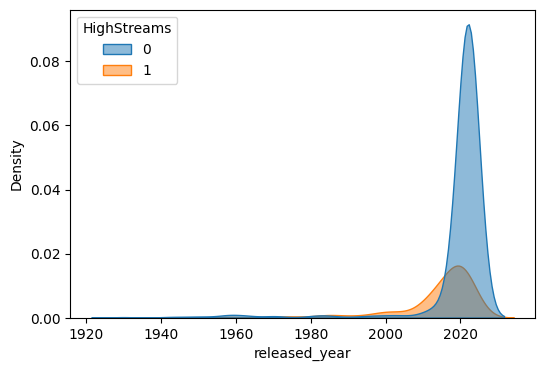

In [183]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='released_year', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# Na osnovu grafikona vidimo da varijabla released_year ima različitu raspodelu za pesme sa visokim i niskim brojem puštanja, što ukazuje da bi released_year mogla biti značajna varijabla za predviđanje

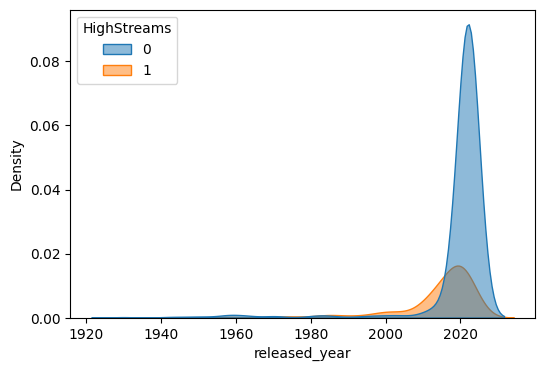

In [83]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=data, x='released_year', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

In [7]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=data, x='in_spotify_playlists', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

data.drop(columns='in_spotify_playlists', inplace=True)

<Figure size 600x400 with 0 Axes>

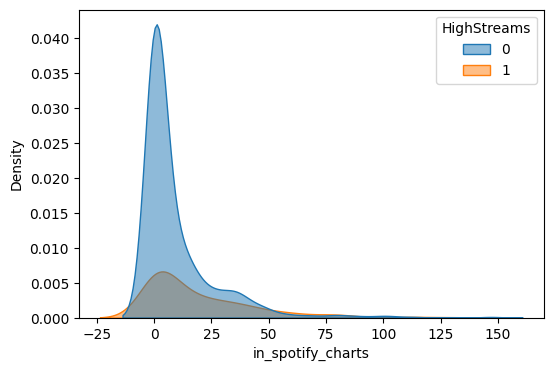

In [93]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=data, x='in_spotify_charts', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

data.drop(columns='in_spotify_charts', inplace=True)

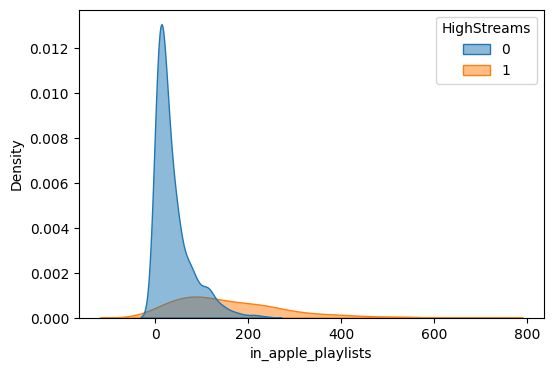

In [88]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=data, x='in_apple_playlists', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

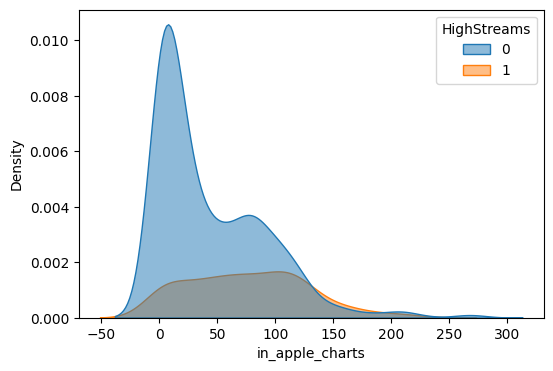

In [91]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=data, x='in_apple_charts', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

data.drop(columns='in_apple_charts', inplace=True)

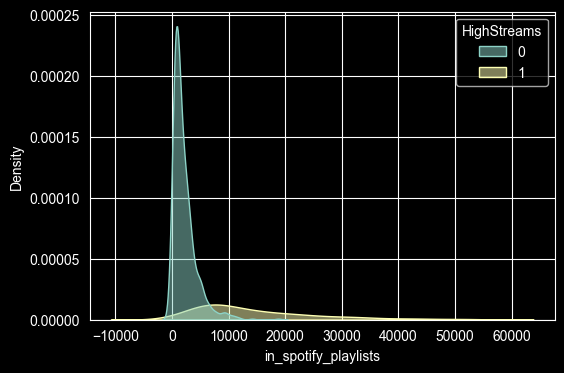

In [8]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='in_spotify_playlists', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# Na osnovu grafikona vidimo da varijabla in_spotify_playlists ima različitu raspodelu za pesme sa visokim i niskim brojem puštanja. Pesme koje se nalaze na većem broju Spotify plejlista češće imaju veći broj puštanja, pa ova varijabla može biti značajna za predviđanje

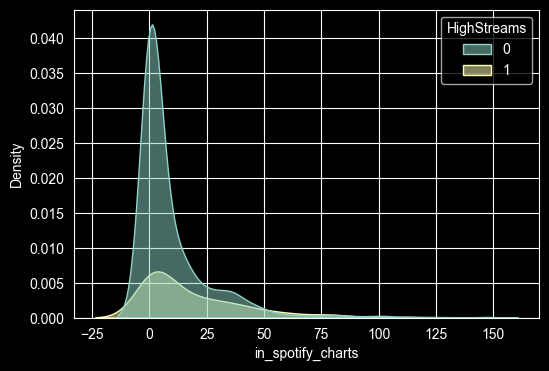

In [9]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='in_spotify_charts', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# Na osnovu grafikona vidimo da varijabla in_spotify_charts ima različitu raspodelu za pesme sa visokim i niskim brojem puštanja. Pesme koje su bolje rangirane na Spotify listi (manji broj pozicije) češće imaju veći broj puštanja, pa ova varijabla može biti značajna za predviđanje

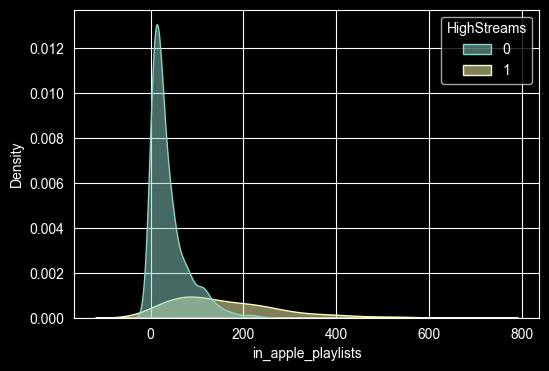

In [10]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='in_apple_playlists', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# Na osnovu grafikona vidimo da varijabla in_apple_playlists ima različitu raspodelu za pesme sa visokim i niskim brojem puštanja. Pesme koje se nalaze na većem broju Apple plejlista češće imaju veći broj puštanja, pa ova varijabla može biti značajna za predviđanje

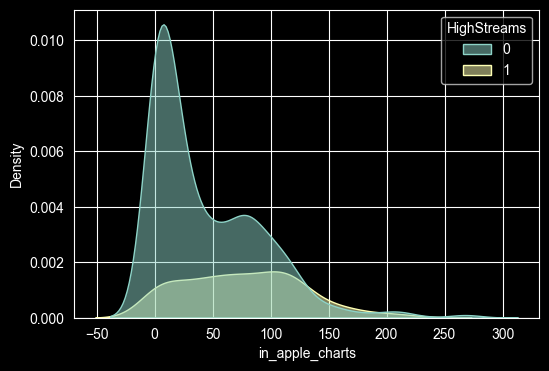

In [11]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='in_apple_charts', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# Na osnovu grafikona vidimo da varijabla in_apple_charts ima različitu raspodelu za pesme sa visokim i niskim brojem puštanja. Pesme koje su bolje rangirane na Apple listi (manji broj pozicije) češće imaju veći broj puštanja, pa ova varijabla može biti značajna za predviđanje


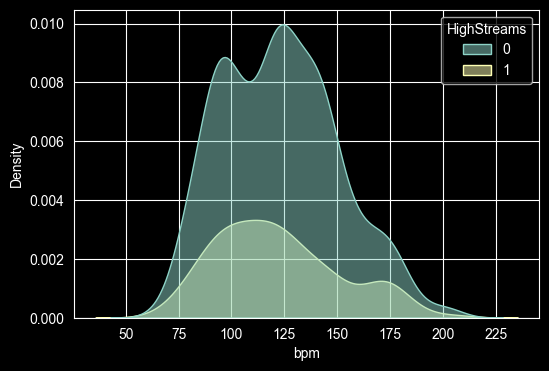

In [12]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='bpm', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# Na osnovu grafikona vidimo da varijabla bpm ima sličnu raspodelu za pesme sa visokim i niskim brojem puštanja. Zato ovu varijablu možemo izostaviti, izbacujemo je
df.drop(columns='bpm', inplace=True)

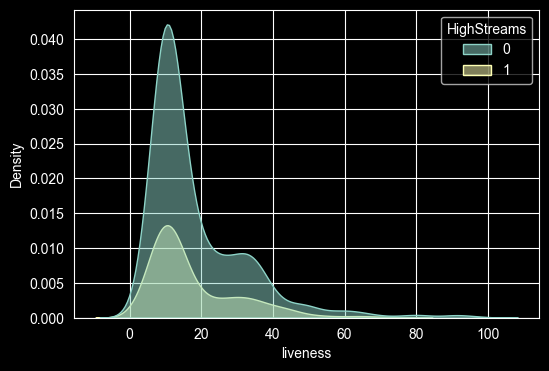

In [13]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='liveness', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# Na osnovu grafikona vidimo da varijabla liveness ima sličnu raspodelu za pesme sa visokim i niskim brojem puštanja. Zato ovu varijablu možemo izostaviti, izbacujemo je
df.drop(columns='liveness', inplace=True)

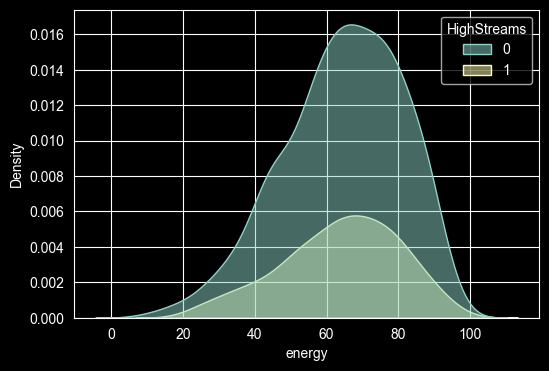

In [14]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='energy', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# Na osnovu grafikona vidimo da varijabla energy ima sličnu raspodelu za pesme sa visokim i niskim brojem puštanja. Zato ovu varijablu možemo izostaviti, izbacujemo je
df.drop(columns='energy', inplace=True)

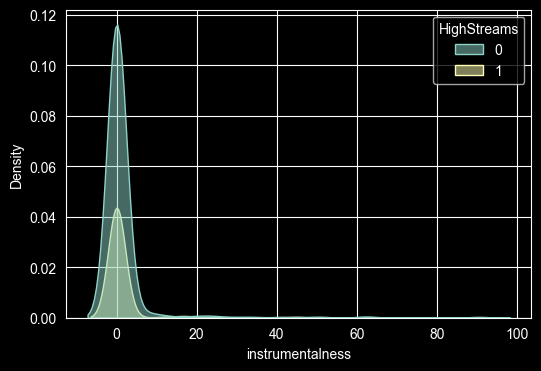

In [15]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='instrumentalness', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# Na osnovu grafikona vidimo da varijabla instrumentalness ima sličnu raspodelu za pesme sa visokim i niskim brojem puštanja. Zato ovu varijablu možemo izostaviti, izbacujemo je
df.drop(columns='instrumentalness', inplace=True)

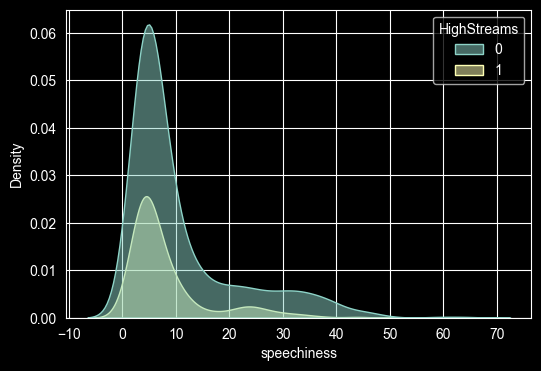

In [16]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='speechiness', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# Na osnovu grafikona vidimo da varijabla speechiness ima sličnu raspodelu za pesme sa visokim i niskim brojem puštanja. Zato ovu varijablu možemo izostaviti, izbacujemo je
df.drop(columns='speechiness', inplace=True)

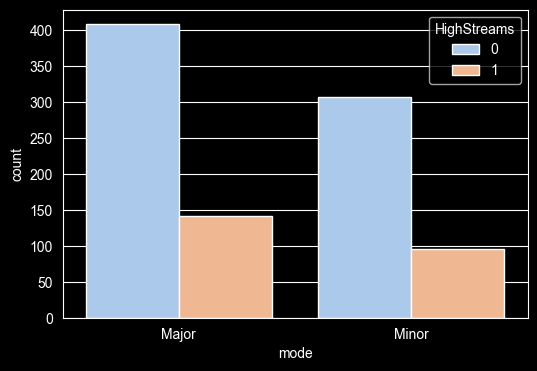

In [17]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='mode', hue='HighStreams', palette='pastel')
plt.show()

# Na osnovu grafikona vidimo da pesme u minor modu imaju malo veću šansu da imaju manji broj puštanja. Iako ne deluje kao toliko jak prediktor kao neke od prethodnih varijabli, može biti značajna pa je ostavljamo

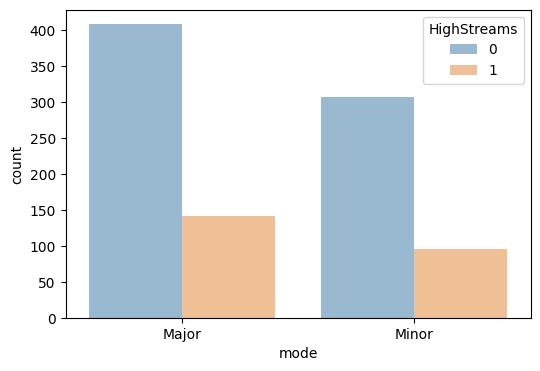

In [96]:
plt.figure(figsize=(6,4))
sns.countplot(data=data, x='mode', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

## Skaliranje numeričkih varijabli


In [18]:
print(df.describe())
print(df.info())

       released_year  in_spotify_playlists  in_spotify_charts  \
count     953.000000            953.000000         953.000000   
mean     2018.238195           5200.124869          11.853095   
std        11.116218           7897.608990          19.320751   
min      1930.000000             31.000000           0.000000   
25%      2020.000000            875.000000           0.000000   
50%      2022.000000           2224.000000           3.000000   
75%      2022.000000           5542.000000          16.000000   
max      2023.000000          52898.000000         147.000000   

       in_apple_playlists  in_apple_charts  HighStreams  
count          953.000000       953.000000   953.000000  
mean            67.812172        51.665268     0.249738  
std             86.441493        50.376630     0.433088  
min              0.000000         0.000000     0.000000  
25%             13.000000         7.000000     0.000000  
50%             34.000000        38.000000     0.000000  
75%     

In [97]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   released_year       953 non-null    int64
 1   in_apple_playlists  953 non-null    int64
 2   bpm                 953 non-null    int64
 3   mode                953 non-null    str  
 4   energy              953 non-null    int64
 5   instrumentalness    953 non-null    int64
 6   liveness            953 non-null    int64
 7   speechiness         953 non-null    int64
 8   HighStreams         953 non-null    int64
dtypes: int64(8), str(1)
memory usage: 67.1 KB
None


In [19]:
numeric_vars = ['released_year', 'in_spotify_playlists', 'in_spotify_charts', 'in_apple_playlists', 'in_apple_charts']
var_num = ['released_year', 'in_spotify_playlists', 'in_spotify_charts', 'in_apple_playlists', 'in_apple_charts']

Proveravamo da li numeričke varijable imaju autlajere kako bismo odlučili da li ćemo koristiti `normalizaciju` ili `standardizaciju` za skaliranje podataka. Ako varijable nemaju autlajere, koristićemo normalizaciju, a ako imaju, koristićemo standardizaciju.


In [20]:
# Funkcija za izračunavanje broja autlajera
def count_outliers(variable):
    q1 = variable.quantile(0.25)
    q3 = variable.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return ((variable < lower) | (variable > upper)).sum()

outliers_per_column = df[numeric_vars].apply(count_outliers)
print("Broj autlajera po kolonama:\n", outliers_per_column)
# Sve varijable imaju autlajere, tako da ćemo koristiti standardizaciju

Broj autlajera po kolonama:
 released_year           151
in_spotify_playlists    109
in_spotify_charts        76
in_apple_playlists       78
in_apple_charts          12
dtype: int64


In [13]:
def num_outliers(var):
    w1=var.quantile(0.25)
    w2 = var.quantile(0.75)
    iwr = w2 - w1
    down = w1- 1.5*iwr
    up = w2 + 1.5*iwr
    return ((var < down) | (var > up)).sum()
col_outliers = df[var_num].apply(num_outliers)
print("Broj autlajera po kolonama:\n", col_outliers)

Broj autlajera po kolonama:
 released_year           151
in_spotify_playlists    109
in_spotify_charts        76
in_apple_playlists       78
in_apple_charts          12
dtype: int64


In [21]:
# Proveravamo da li varijable imaju normalnu raspodelu kako bismo odlučili na koji način da izvršimo standardizaciju
shapiro_results = df[numeric_vars].apply(lambda x: shapiro(x)[1])
print("Shapiro-Wilk p-vrednosti:\n", shapiro_results)

# Sve varijable imaju p-vrednosti < 0.05, što znači da nemaju normalnu raspodelu
# Zbog toga ćemo ih standardizovati pomoću RobustScaler-a, koji koristi median i IQR (interkvartilni opseg, razlika između 3. i 1. kvartila)

Shapiro-Wilk p-vrednosti:
 released_year           1.210310e-47
in_spotify_playlists    2.585440e-41
in_spotify_charts       1.284461e-39
in_apple_playlists      4.262281e-37
in_apple_charts         4.332586e-26
dtype: float64


In [51]:
for col in ['released_year', 'in_spotify_playlists', 'in_spotify_charts', 'in_apple_playlists', 'in_apple_charts']:
    state, r= shapiro(data[col].dropna())
    print(f"{col}: r: {r:.60f}",)

released_year: r: 0.000000000000000000000000000000000000000000000012103096460079
in_spotify_playlists: r: 0.000000000000000000000000000000000000000025854400654100747438
in_spotify_charts: r: 0.000000000000000000000000000000000000001284460584230255013411
in_apple_playlists: r: 0.000000000000000000000000000000000000426228101891950575890442
in_apple_charts: r: 0.000000000000000000000000043325862554849968861628027847843499


In [52]:
rob_s = RobustScaler()
data_sub = pd.DataFrame()
data_sub = rob_s.fit_transform(data[var_num])

In [53]:
print(data.info())


<class 'pandas.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   track_name            953 non-null    str    
 1   released_year         953 non-null    int64  
 2   in_spotify_playlists  953 non-null    int64  
 3   in_spotify_charts     953 non-null    float64
 4   in_apple_playlists    953 non-null    int64  
 5   in_apple_charts       953 non-null    float64
 6   bpm                   953 non-null    int64  
 7   mode                  0 non-null      float64
 8   energy                953 non-null    int64  
 9   instrumentalness      953 non-null    int64  
 10  liveness              953 non-null    int64  
 11  speechiness           953 non-null    int64  
 12  HighStreams           953 non-null    int64  
dtypes: float64(3), int64(9), str(1)
memory usage: 96.9 KB
None


In [22]:
# Standardizujemo numeričke varijable pomoću RobustScaler-a
robust_scaler = RobustScaler()
df_st = pd.DataFrame() # Kreiramo prazan DataFrame u koji ćemo ubaciti sve vrednosti pripremljene za KNN
df_st[numeric_vars] = robust_scaler.fit_transform(df[numeric_vars])

### Transformacija binarnih i kategorijskih varijabli u numeričke


In [23]:
print(df.info())
# Jedina varijabla koja nije numerička je mode

<class 'pandas.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         953 non-null    int64  
 1   in_spotify_playlists  953 non-null    int64  
 2   in_spotify_charts     953 non-null    float64
 3   in_apple_playlists    953 non-null    int64  
 4   in_apple_charts       953 non-null    float64
 5   mode                  953 non-null    str    
 6   HighStreams           953 non-null    int64  
dtypes: float64(2), int64(4), str(1)
memory usage: 52.2 KB
None


In [24]:
print(df['mode'].unique())
# Varijabla mode ima samo dve vrednosti ('Major' i 'Minor'), binarna je i možemo je mapirati u brojeve (npr. 0 i 1)
df_st['mode'] = df['mode'].map({'Major': 0, 'Minor': 1})

<StringArray>
['Major', 'Minor']
Length: 2, dtype: str


In [32]:
data['HighStreams'] = data['HighStreams']

In [26]:
# Dodajemo i izlaznu varijablu HighStreams u standardizovani DataFrame
df_st['HighStreams'] = df['HighStreams']

### Podela na trening i test skupove

In [27]:
# Delimo podatke na trening (80%) i test (20%) skup

X = df_st.drop(columns='HighStreams')
y = df_st['HighStreams']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

### Izračunavanje optimalne vrednosti za parametar `k`

In [28]:
knn = KNeighborsClassifier()

# Koristimo neparne vrednosti za k (broj suseda) u opsegu od 3 do 25 kako bi uvek postojala dominantna klasa
param_grid = {'n_neighbors': list(range(3, 26, 2))}

# Primenjujemo kros validaciju sa 10 iteracija
cv = GridSearchCV(estimator=knn,
                  param_grid=param_grid,
                  cv=10,
                  scoring='accuracy',
                  verbose = 1,
                  n_jobs = -1)
cv.fit(X_train, y_train)

best_k = cv.best_params_['n_neighbors']
print("Optimalna vrednost za k:", best_k)
# Dobili smo da nam je optimalna vrednost za parametar k=11

Optimalna vrednost za k: 11


### Kreiranje KNN klasifikatora na osnovu dobijene vrednosti za k


In [29]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",11
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [32]:
y_pred = knn.predict(X_test)

### Kreiranje matrice konfuzije

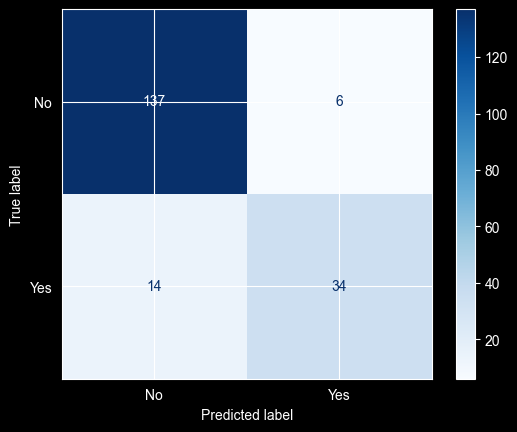

In [31]:
cm_knn = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn,
                              display_labels=['No', 'Yes'])
disp.plot(cmap=plt.cm.Blues)
plt.show()

#### Interpretacija matrice konfuzije

- **True positive (TP)** – za 34 pesama smo predvideli da će imati veliki broj puštanja i one zaista imaju veliki broj puštanja
- **True negative (TN)** – za 137 pesama smo predvideli da neće imati veliki broj puštanja i one zaista nemaju veliki broj puštanja
- **False positive (FP)** – za 6 pesama smo predvideli da će imati veliki broj puštanja, a one zapravo nemaju veliki broj puštanja
- **False negative (FN)** – za 14 pesama smo predvideli da neće imati veliki broj puštanja, a one zapravo imaju veliki broj puštanja

Na glavnoj dijagonali matrice (34 i 137) nalaze se tačne predikcije, dok se na sporednoj dijagonali (6 i 14) nalaze pogrešne predikcije.


### Evaluacione metrike

4 metrike koje se najčešće koriste za procenu uspešnosti klasifikatora su:

- **Accuracy (tačnost)** – procenat tačnih predikcija (i pozitivnih i negativnih) u odnosu na sve observacije
- **Precision (preciznost)** – procenat observacija za koje smo predvideli da su pozitivne i koje zaista jesu pozitivne
- **Recall (odziv)** – procenat observacija koje su stvarno pozitivne i koje smo mi tačno predvideli kao pozitivne
- **F1 score** – mera za balansiranje vrednosti precision-a i recall-a


In [33]:
def compute_eval_metrics(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, pos_label=1)
    recall = recall_score(y_true, y_pred, pos_label=1)
    f1 = f1_score(y_true, y_pred, pos_label=1)
    return {
        'accuracy': accuracy,
        'precision': float(precision),
        'recall': float(recall),
        'f1': float(f1)
    }

In [34]:
knn_eval = compute_eval_metrics(y_test, y_pred)
print(knn_eval)

{'accuracy': 0.8952879581151832, 'precision': 0.85, 'recall': 0.7083333333333334, 'f1': 0.7727272727272727}


Tumačenje metrika u kontekstu problema koji se rešava u zadatku:
- **Accuracy** – za 89.53% pesama smo tačno predvideli da li će imati veliki broj puštanja ili ne
- **Precision** – od svih pesama za koje smo predvideli da će imati veliki broj puštanja, 85% zaista ima veliki broj puštanja
- **Recall** – od svih pesama koje zaista imaju veliki broj puštanja, mi smo tačno predvideli 70.83% njih
- **F1 score** – mera koja balansira preciznost i odziv, i u našem slučaju iznosi 0.77. Može se reći da naš model uspešno balansira između sposobnosti da prepozna većinu pesama koje zaista imaju veliki broj puštanja i toga da ne označava previše pesama kao pesme sa velikim brojem puštanja kada one to zapravo nisu.


**Napomena:** Date interpretacije u ovom rešenju predstavljaju samo jedan od mogućih načina formulacije odgovora na zahtev zadatka.
